# MODMA MDD vs Healthy Control — FBCSP + RBF-SVM

**Member 3 implementation**

This notebook:
1. Loads `modma_epochs.npz` (`X`, `y`, `subject_id`, optionally `ch_names`).
2. Creates a five-band filter bank (delta, theta, alpha, beta, gamma).
3. Learns CSP spatial filters **inside each training fold only**.
4. Trains an RBF-SVM.
5. Uses **StratifiedGroupKFold with participant IDs as groups** so epochs from one participant never appear in both train and test.
6. Aggregates epoch decision scores per participant and reports participant-level accuracy, balanced accuracy, ROC-AUC, and confusion matrix.

**Dataset assumptions from the project handoff:** `X` has shape `(epochs, 128, 1000)`, sampling rate is 250 Hz, labels are `0 = Healthy Control` and `1 = MDD`, and `subject_id` identifies the participant for every epoch. Check the inspection cell and change the settings if your actual NPZ differs.

> **GPU note:** FBCSP and scikit-learn's SVM are CPU algorithms in this implementation. A Colab GPU runtime is not required and will not automatically accelerate this pipeline. Use a High-RAM runtime if available. The notebook uses disk-backed filter-bank caches to avoid keeping all filtered bands in RAM.

## 1. Colab setup and locate the NPZ

Recommended: put `modma_epochs.npz` in Google Drive, then mount Drive. If you prefer, use the upload cell instead (a ~2 GB upload may take a while).

In [4]:
# Install only what this notebook needs
!pip -q install numpy scipy scikit-learn pandas matplotlib seaborn

In [5]:
from google.colab import drive
drive.mount('/content/drive')

# Edit this path to match the location of your file in Google Drive.
NPZ_PATH = '/content/drive/MyDrive/modma_epochs.npz'

# Alternative: upload from your computer (use instead of the Drive path above).
# from google.colab import files
# uploaded = files.upload()
# NPZ_PATH = '/content/' + next(iter(uploaded))


Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [6]:
import os, gc, json, warnings, shutil, time
from pathlib import Path

import numpy as np
import pandas as pd
import scipy.signal as signal
from scipy.linalg import eigh

from sklearn.model_selection import StratifiedGroupKFold
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC
from sklearn.metrics import (
    accuracy_score, balanced_accuracy_score, roc_auc_score,
    confusion_matrix, classification_report
)

SEED = 42
SFREQ = 250.0
N_SPLITS = 10
N_CSP_COMPONENTS = 4       # total selected CSP components per frequency band
FILTER_ORDER = 4
FILTER_CHUNK_SIZE = 24     # reduce if RAM is limited
FEATURE_CHUNK_SIZE = 64

# Five conventional EEG frequency bands (Hz).
BANDS = {
    'delta': (1.0, 4.0),
    'theta': (4.0, 8.0),
    'alpha': (8.0, 13.0),
    'beta':  (13.0, 30.0),
    'gamma': (30.0, 45.0),
}

CACHE_DIR = Path('/content/fbcsp_filter_cache')
CACHE_DIR.mkdir(parents=True, exist_ok=True)

assert os.path.exists(NPZ_PATH), f'Cannot find NPZ file: {NPZ_PATH}'
print('NPZ:', NPZ_PATH)
print('Cache directory:', CACHE_DIR)
print('Free disk space (GB):', round(shutil.disk_usage('/content').free / 1e9, 2))


NPZ: /content/drive/MyDrive/modma_epochs.npz
Cache directory: /content/fbcsp_filter_cache
Free disk space (GB): 120.83


## 2. Load and validate the MODMA arrays

The notebook expects one binary label and one participant ID per epoch. It does **not** infer participant IDs from row order. If your file uses different key names or label encoding, update the mapping in this cell rather than silently proceeding.

In [7]:
npz = np.load(NPZ_PATH, allow_pickle=False)
print('Available keys:', npz.files)

required = {'X', 'y', 'subject_id'}
missing = required - set(npz.files)
if missing:
    raise KeyError(f'Missing required NPZ keys: {missing}. Available keys: {npz.files}')

X = npz['X']
y = np.asarray(npz['y']).reshape(-1)
subject_id = np.asarray(npz['subject_id']).reshape(-1)
ch_names = npz['ch_names'] if 'ch_names' in npz.files else None

print('X shape:', X.shape, 'dtype:', X.dtype)
print('y shape:', y.shape, 'unique labels:', np.unique(y, return_counts=True))
print('subject_id shape:', subject_id.shape, 'unique participants:', len(np.unique(subject_id)))
print('ch_names:', None if ch_names is None else np.asarray(ch_names).shape)

if X.ndim != 3:
    raise ValueError(f'Expected X with shape (epochs, channels, samples), got {X.shape}')
if len(X) != len(y) or len(X) != len(subject_id):
    raise ValueError('X, y and subject_id must have the same number of epochs.')
if X.shape[-1] < 100:
    raise ValueError('The last axis should contain time samples; check whether X is (epochs, channels, samples).')
if not np.isfinite(y).all():
    raise ValueError('Labels contain NaN or Inf.')
if not np.isfinite(subject_id).all():
    raise ValueError('subject_id contains NaN or Inf.')

# Convert common string labels if necessary. Expected final labels: 0=HC, 1=MDD.
unique_labels = set(np.unique(y).tolist())
if unique_labels == {'HC', 'MDD'}:
    y = np.where(y == 'MDD', 1, 0)
elif unique_labels == {'0', '1'}:
    y = y.astype(int)
else:
    y = y.astype(int)

if set(np.unique(y).tolist()) != {0, 1}:
    raise ValueError(f'Expected binary labels 0 and 1; found {np.unique(y)}. Map labels explicitly.')

# Every participant must have exactly one diagnosis label.
participant_label_counts = pd.DataFrame({'subject_id': subject_id, 'y': y}).groupby('subject_id')['y'].nunique()
if (participant_label_counts != 1).any():
    raise ValueError('At least one participant has inconsistent labels across epochs.')

# Float32 reduces memory use. Keep X in RAM; filtered bands are stored on disk.
X = np.asarray(X, dtype=np.float32)
print('\nClass mapping: 0=Healthy Control, 1=MDD')
print('Epochs:', len(X), '| Channels:', X.shape[1], '| Samples:', X.shape[2])
print('Participants by class:')
print(pd.DataFrame({'subject_id': subject_id, 'y': y}).drop_duplicates('subject_id')['y'].value_counts().sort_index())


Available keys: ['X', 'y', 'subject_id', 'ch_names', 'subject_str_id']
X shape: (4002, 128, 1000) dtype: float32
y shape: (4002,) unique labels: (array([0, 1]), array([2192, 1810]))
subject_id shape: (4002,) unique participants: 53
ch_names: (128,)

Class mapping: 0=Healthy Control, 1=MDD
Epochs: 4002 | Channels: 128 | Samples: 1000
Participants by class:
y
0    29
1    24
Name: count, dtype: int64


## 3. Filter-bank preprocessing

Each epoch is filtered independently using a zero-phase Butterworth band-pass filter. Filtering itself does not learn from labels; the CSP spatial filters are fitted later using only each training fold.

The cache uses one disk-backed float32 file per frequency band. This needs approximately `number_of_bands × X.nbytes` free disk space (about 10 GB for a 2 GB input and five bands).

In [8]:
def make_sos(low, high, sfreq=SFREQ, order=FILTER_ORDER):
    nyquist = sfreq / 2.0
    if not (0 < low < high < nyquist):
        raise ValueError(f'Invalid band {low}-{high} Hz for sampling rate {sfreq} Hz.')
    return signal.butter(order, [low, high], btype='bandpass', fs=sfreq, output='sos')


def build_filter_bank_cache(X, bands, cache_dir, chunk_size=FILTER_CHUNK_SIZE):
    n_epochs, n_channels, n_times = X.shape
    cache_paths = {}
    required_bytes = len(bands) * n_epochs * n_channels * n_times * np.dtype(np.float32).itemsize
    free_bytes = shutil.disk_usage(str(cache_dir)).free
    print(f'Approx. cache size: {required_bytes / 1e9:.2f} GB; free disk: {free_bytes / 1e9:.2f} GB')
    if required_bytes > free_bytes * 0.90:
        raise RuntimeError('Not enough free disk space for all filter-bank caches. Free space or use fewer bands.')

    for band_name, (low, high) in bands.items():
        path = cache_dir / f'{band_name}.dat'
        expected_size = n_epochs * n_channels * n_times * 4
        if path.exists() and path.stat().st_size == expected_size:
            print(f'Reusing cache: {band_name}')
            cache_paths[band_name] = path
            continue

        if path.exists():
            path.unlink()
        print(f'Filtering {band_name}: {low}-{high} Hz')
        mm = np.memmap(path, mode='w+', dtype=np.float32,
                       shape=(n_epochs, n_channels, n_times))
        sos = make_sos(low, high)
        for start in range(0, n_epochs, chunk_size):
            end = min(start + chunk_size, n_epochs)
            batch = signal.sosfiltfilt(sos, X[start:end], axis=-1)
            mm[start:end] = batch.astype(np.float32, copy=False)
            if start == 0 or end == n_epochs or (start // chunk_size) % 20 == 0:
                print(f'  {end}/{n_epochs} epochs', end='\r')
        mm.flush()
        del mm
        print(f'\nSaved {path}')
        cache_paths[band_name] = path
        gc.collect()
    return cache_paths


cache_paths = build_filter_bank_cache(X, BANDS, CACHE_DIR)
print('Filter-bank caches ready:', list(cache_paths))


Approx. cache size: 10.25 GB; free disk: 118.78 GB
Filtering delta: 1.0-4.0 Hz
  4002/4002 epochs
Saved /content/fbcsp_filter_cache/delta.dat
Filtering theta: 4.0-8.0 Hz
  4002/4002 epochs
Saved /content/fbcsp_filter_cache/theta.dat
Filtering alpha: 8.0-13.0 Hz
  4002/4002 epochs
Saved /content/fbcsp_filter_cache/alpha.dat
Filtering beta: 13.0-30.0 Hz
  4002/4002 epochs
Saved /content/fbcsp_filter_cache/beta.dat
Filtering gamma: 30.0-45.0 Hz
  4002/4002 epochs
Saved /content/fbcsp_filter_cache/gamma.dat
Filter-bank caches ready: ['delta', 'theta', 'alpha', 'beta', 'gamma']


## 4. CSP implementation

For each frequency band, CSP learns spatial filters from the training epochs only. Per-epoch covariance matrices are trace-normalized, class-average covariances are calculated, and a regularized generalized eigenvalue problem is solved. The selected filters from both ends of the eigenvalue spectrum are used to calculate log-variance features.

In [9]:
def epoch_covariances(batch, eps=1e-10):
    # batch: (epochs, channels, time)
    centered = batch - batch.mean(axis=-1, keepdims=True)
    covs = np.einsum('bct,bdt->bcd', centered, centered, optimize=True)
    traces = np.trace(covs, axis1=1, axis2=2)
    covs /= np.maximum(traces[:, None, None], eps)
    return covs


def fit_csp_from_memmap(mm, train_indices, y_train, n_components=N_CSP_COMPONENTS,
                        chunk_size=FEATURE_CHUNK_SIZE, reg=1e-6):
    classes = np.unique(y_train)
    if len(classes) != 2:
        raise ValueError(f'CSP requires two classes in each training fold; got {classes}')

    class_cov_sum = {int(c): None for c in classes}
    class_count = {int(c): 0 for c in classes}

    for start in range(0, len(train_indices), chunk_size):
        idx = train_indices[start:start + chunk_size]
        batch = np.asarray(mm[idx], dtype=np.float32)
        covs = epoch_covariances(batch)
        labels_batch = y_train[start:start + len(idx)]

        for c in classes:
            mask = labels_batch == c
            if np.any(mask):
                partial = covs[mask].sum(axis=0, dtype=np.float64)
                key = int(c)
                if class_cov_sum[key] is None:
                    class_cov_sum[key] = partial
                else:
                    class_cov_sum[key] += partial
                class_count[key] += int(mask.sum())

    cov0 = class_cov_sum[int(classes[0])] / class_count[int(classes[0])]
    cov1 = class_cov_sum[int(classes[1])] / class_count[int(classes[1])]
    composite = cov0 + cov1
    composite += reg * np.trace(composite) / composite.shape[0] * np.eye(composite.shape[0])

    # Generalized eigenvectors: cov1 * w = lambda * (cov0 + cov1) * w
    eigenvalues, eigenvectors = eigh(cov1, composite, check_finite=False)
    order = np.argsort(eigenvalues)
    n_components = min(n_components, eigenvectors.shape[1])
    n_low = n_components // 2
    n_high = n_components - n_low
    selected = np.concatenate([order[:n_low], order[-n_high:]]) if n_low else order[-n_high:]
    return eigenvectors[:, selected].astype(np.float32)


def csp_logvar_features(mm, indices, filters, chunk_size=FEATURE_CHUNK_SIZE, eps=1e-10):
    n_components = filters.shape[1]
    features = np.empty((len(indices), n_components), dtype=np.float32)

    for start in range(0, len(indices), chunk_size):
        end = min(start + chunk_size, len(indices))
        idx = indices[start:end]
        batch = np.asarray(mm[idx], dtype=np.float32)
        # Spatial projection: (epochs, components, time)
        projected = np.einsum('ck,bct->bkt', filters, batch, optimize=True)
        variances = np.var(projected, axis=-1)
        normalized = variances / np.maximum(variances.sum(axis=1, keepdims=True), eps)
        features[start:end] = np.log(np.maximum(normalized, eps))
    return features


print('CSP functions defined.')


CSP functions defined.


## 5. Participant-level 10-fold cross-validation (baseline)

`StratifiedGroupKFold` keeps all epochs from a participant in a single fold while approximately preserving class proportions. For each fold, the CSP filters, scaler, and SVM are fitted only on training participants.

The final prediction for a participant is obtained by averaging that participant's epoch-level SVM decision scores. This produces one out-of-fold score and one prediction per participant.

In [10]:
# Map each participant ID to its single diagnosis label.
participant_table = (
    pd.DataFrame({'subject_id': subject_id, 'y': y})
    .drop_duplicates('subject_id')
    .sort_values('subject_id')
    .reset_index(drop=True)
)
print('Participants:', len(participant_table))
print(participant_table['y'].value_counts().rename(index={0:'HC', 1:'MDD'}))

cv = StratifiedGroupKFold(n_splits=N_SPLITS, shuffle=True, random_state=SEED)
all_indices = np.arange(len(y))

oof_subject_rows = []
fold_rows = []
fold_subject_sets = []

start_time = time.time()

for fold, (train_idx, test_idx) in enumerate(cv.split(X, y, groups=subject_id), start=1):
    print(f'\n========== Fold {fold}/{N_SPLITS} ==========')

    train_subjects = set(subject_id[train_idx].tolist())
    test_subjects = set(subject_id[test_idx].tolist())
    assert train_subjects.isdisjoint(test_subjects), 'Participant leakage detected!'
    fold_subject_sets.append(test_subjects)

    y_train = y[train_idx]
    feature_train_parts = []
    feature_test_parts = []

    # Fit one CSP spatial filter bank per fold, using training data only.
    for band_name in BANDS:
        print('Band:', band_name)
        mm = np.memmap(cache_paths[band_name], mode='r', dtype=np.float32,
                       shape=X.shape)

        filters = fit_csp_from_memmap(mm, train_idx, y_train)
        f_train = csp_logvar_features(mm, train_idx, filters)
        f_test = csp_logvar_features(mm, test_idx, filters)

        feature_train_parts.append(f_train)
        feature_test_parts.append(f_test)
        del mm, filters, f_train, f_test
        gc.collect()

    X_train_features = np.concatenate(feature_train_parts, axis=1)
    X_test_features = np.concatenate(feature_test_parts, axis=1)

    scaler = StandardScaler()
    X_train_scaled = scaler.fit_transform(X_train_features)
    X_test_scaled = scaler.transform(X_test_features)

    svm = SVC(
        kernel='rbf',
        C=1.0,
        gamma='scale',
        class_weight='balanced',
        probability=False,
        random_state=SEED
    )
    svm.fit(X_train_scaled, y_train)
    epoch_scores = svm.decision_function(X_test_scaled)

    # Aggregate epoch scores to one score per held-out participant.
    fold_df = pd.DataFrame({
        'subject_id': subject_id[test_idx],
        'y_true': y[test_idx],
        'decision_score': epoch_scores
    })
    subject_df = (
        fold_df.groupby('subject_id', sort=False)
        .agg(y_true=('y_true', 'first'),
             decision_score=('decision_score', 'mean'),
             n_epochs=('y_true', 'size'))
        .reset_index()
    )
    subject_df['y_pred'] = (subject_df['decision_score'] >= 0).astype(int)
    subject_df['fold'] = fold

    oof_subject_rows.append(subject_df)

    fold_acc = accuracy_score(subject_df.y_true, subject_df.y_pred)
    fold_bacc = balanced_accuracy_score(subject_df.y_true, subject_df.y_pred)
    try:
        fold_auc = roc_auc_score(subject_df.y_true, subject_df.decision_score)
    except ValueError:
        fold_auc = np.nan

    fold_rows.append({
        'fold': fold,
        'n_train_participants': len(train_subjects),
        'n_test_participants': len(test_subjects),
        'accuracy': fold_acc,
        'balanced_accuracy': fold_bacc,
        'roc_auc': fold_auc
    })

    print(f'Participants in test fold: {len(subject_df)}')
    print(f'Accuracy={fold_acc:.4f} | Balanced accuracy={fold_bacc:.4f} | ROC-AUC={fold_auc:.4f}')

    del feature_train_parts, feature_test_parts
    del X_train_features, X_test_features, X_train_scaled, X_test_scaled, scaler, svm
    gc.collect()

print(f'\nCross-validation completed in {(time.time()-start_time)/60:.1f} minutes.')


Participants: 53
y
HC     29
MDD    24
Name: count, dtype: int64

========== Fold 1/10 ==========
Band: delta
Band: theta
Band: alpha
Band: beta
Band: gamma
Participants in test fold: 6
Accuracy=0.5000 | Balanced accuracy=0.6250 | ROC-AUC=0.6250

========== Fold 2/10 ==========
Band: delta
Band: theta
Band: alpha
Band: beta
Band: gamma
Participants in test fold: 6
Accuracy=0.8333 | Balanced accuracy=0.7500 | ROC-AUC=1.0000

========== Fold 3/10 ==========
Band: delta
Band: theta
Band: alpha
Band: beta
Band: gamma
Participants in test fold: 5
Accuracy=1.0000 | Balanced accuracy=1.0000 | ROC-AUC=1.0000

========== Fold 4/10 ==========
Band: delta
Band: theta
Band: alpha
Band: beta
Band: gamma
Participants in test fold: 5
Accuracy=0.6000 | Balanced accuracy=0.6667 | ROC-AUC=0.6667

========== Fold 5/10 ==========
Band: delta
Band: theta
Band: alpha
Band: beta
Band: gamma
Participants in test fold: 5
Accuracy=0.8000 | Balanced accuracy=0.8333 | ROC-AUC=0.6667

========== Fold 6/10 ========

## 6. Final participant-level metrics and confusion matrix

These are pooled out-of-fold participant predictions: every participant is evaluated exactly once by a model that did not train on that participant.

In [11]:
oof = pd.concat(oof_subject_rows, ignore_index=True)
oof = oof.sort_values('subject_id').reset_index(drop=True)

if oof['subject_id'].duplicated().any():
    raise RuntimeError('A participant appeared in more than one test fold.')
if len(oof) != len(participant_table):
    raise RuntimeError(f'Expected {len(participant_table)} participant predictions, got {len(oof)}.')

y_true_subject = oof['y_true'].to_numpy()
y_pred_subject = oof['y_pred'].to_numpy()
subject_scores = oof['decision_score'].to_numpy()

accuracy = accuracy_score(y_true_subject, y_pred_subject)
balanced_acc = balanced_accuracy_score(y_true_subject, y_pred_subject)
roc_auc = roc_auc_score(y_true_subject, subject_scores)
cm = confusion_matrix(y_true_subject, y_pred_subject, labels=[0, 1])

print('PARTICIPANT-LEVEL 10-FOLD CV RESULTS')
print(f'Accuracy:          {accuracy:.4f}')
print(f'Balanced accuracy: {balanced_acc:.4f}')
print(f'ROC-AUC:           {roc_auc:.4f}')
print('\nConfusion matrix (rows=true, columns=predicted; order [HC, MDD]):')
print(cm)
print('\nClassification report:')
print(classification_report(
    y_true_subject, y_pred_subject,
    labels=[0, 1], target_names=['Healthy Control', 'MDD'], digits=4,
    zero_division=0
))

fold_results = pd.DataFrame(fold_rows)
print('\nPer-fold participant-level metrics:')
display(fold_results)
print('\nMean ± SD across folds (folds can contain different participant counts):')
display(fold_results[['accuracy', 'balanced_accuracy', 'roc_auc']].agg(['mean', 'std']))



PARTICIPANT-LEVEL 10-FOLD CV RESULTS
Accuracy:          0.6415
Balanced accuracy: 0.6437
ROC-AUC:           0.6480

Confusion matrix (rows=true, columns=predicted; order [HC, MDD]):
[[18 11]
 [ 8 16]]

Classification report:
                 precision    recall  f1-score   support

Healthy Control     0.6923    0.6207    0.6545        29
            MDD     0.5926    0.6667    0.6275        24

       accuracy                         0.6415        53
      macro avg     0.6425    0.6437    0.6410        53
   weighted avg     0.6472    0.6415    0.6423        53


Per-fold participant-level metrics:


,fold,n_train_participants,n_test_participants,accuracy,balanced_accuracy,roc_auc
0,1,47,6,0.500000,0.625000,0.625000
1,2,47,6,0.833333,0.750000,1.000000
2,3,48,5,1.000000,1.000000,1.000000
3,4,48,5,0.600000,0.666667,0.666667
4,5,48,5,0.800000,0.833333,0.666667
5,6,48,5,0.200000,0.250000,0.333333
6,7,48,5,0.600000,0.750000,1.000000
7,8,48,5,0.800000,0.833333,0.666667
8,9,47,6,0.500000,0.500000,0.333333
9,10,48,5,0.600000,0.583333,0.833333



Mean ± SD across folds (folds can contain different participant counts):


,accuracy,balanced_accuracy,roc_auc
mean,0.643333,0.679167,0.712500
std,0.225010,0.207916,0.250347


## 6. Leave-One-Subject-Out (LOSO) evaluation

This additional evaluation holds out **one complete participant at a time**. With 53 participants, it runs 53 outer folds. No epoch from the held-out participant is used to fit CSP, scaling, or the SVM.

Within each outer training set, the SVM hyperparameters are selected using group-aware inner cross-validation. Inner folds keep each participant together. The CSP representation is fitted on the complete outer training set before this SVM-only search, so inner search scores are tuning proxies rather than unbiased nested-CV estimates. The outer held-out participant remains untouched, so the final LOSO metrics are calculated on genuinely held-out participants after aggregating epoch scores.

**Runtime note:** LOSO is substantially more computationally expensive than 10-fold CV because the filter-bank CSP features are refitted for every held-out participant. For a quick first run, set `RUN_LOSO_TUNING = False` to use the fixed SVM settings. The outer LOSO evaluation still remains participant-independent.

In [12]:
from sklearn.model_selection import LeaveOneGroupOut, StratifiedGroupKFold, GridSearchCV

# Keep this True to let inner group-aware CV choose SVM hyperparameters.
# Set False for a faster LOSO run using the fixed baseline SVM settings.
RUN_LOSO_TUNING = True
LOS0_EXPECTED_PARTICIPANTS = 53  # informational check; code adapts if count differs
LOS0_INNER_SPLITS = 4

n_subjects = participant_table['subject_id'].nunique()
print(f'LOSO outer folds: {n_subjects}')
if n_subjects != LOS0_EXPECTED_PARTICIPANTS:
    print(f'NOTE: expected 53 participants, but the loaded data contains {n_subjects}. '
          'LOSO will run once per participant actually present.')

logo = LeaveOneGroupOut()
loso_subject_rows = []
loso_fold_rows = []
loso_start = time.time()

# A modest grid avoids an excessively large search while testing meaningful
# regularization and RBF-kernel scales. Scaling is refitted inside each search fold.
svm_param_grid = {
    'C': [0.1, 1.0, 10.0, 100.0],
    'gamma': ['scale', 0.01, 0.1]
}

for fold, (train_idx, test_idx) in enumerate(
        logo.split(np.zeros(len(y)), y, groups=subject_id), start=1):

    held_out_subject = subject_id[test_idx][0]
    train_subjects = np.unique(subject_id[train_idx])
    assert held_out_subject not in set(train_subjects.tolist()), 'LOSO participant leakage!'

    y_train = y[train_idx]
    feature_train_parts, feature_test_parts = [], []

    for band_name in BANDS:
        mm = np.memmap(cache_paths[band_name], mode='r', dtype=np.float32, shape=X.shape)
        filters = fit_csp_from_memmap(mm, train_idx, y_train)
        feature_train_parts.append(csp_logvar_features(mm, train_idx, filters))
        feature_test_parts.append(csp_logvar_features(mm, test_idx, filters))
        del mm, filters
        gc.collect()

    X_train_features = np.concatenate(feature_train_parts, axis=1)
    X_test_features = np.concatenate(feature_test_parts, axis=1)

    if RUN_LOSO_TUNING and len(train_subjects) >= 3:
        inner_splits = min(LOS0_INNER_SPLITS, len(train_subjects))
        inner_cv = StratifiedGroupKFold(
            n_splits=inner_splits, shuffle=True, random_state=SEED
        )
        base_pipeline = __import__('sklearn.pipeline', fromlist=['Pipeline']).Pipeline([
            ('scaler', StandardScaler()),
            ('svm', SVC(kernel='rbf', class_weight='balanced',
                        probability=False, random_state=SEED))
        ])
        search = GridSearchCV(
            estimator=base_pipeline,
            param_grid={
                'svm__C': svm_param_grid['C'],
                'svm__gamma': svm_param_grid['gamma']
            },
            scoring='roc_auc',
            cv=inner_cv,
            n_jobs=-1,
            refit=True,
            error_score='raise'
        )
        search.fit(X_train_features, y_train, groups=subject_id[train_idx])
        fitted_model = search.best_estimator_
        best_params = search.best_params_
    else:
        fitted_model = __import__('sklearn.pipeline', fromlist=['Pipeline']).Pipeline([
            ('scaler', StandardScaler()),
            ('svm', SVC(kernel='rbf', C=1.0, gamma='scale',
                        class_weight='balanced', probability=False,
                        random_state=SEED))
        ])
        fitted_model.fit(X_train_features, y_train)
        best_params = {'svm__C': 1.0, 'svm__gamma': 'scale'}

    epoch_scores = fitted_model.decision_function(X_test_features)
    heldout_df = pd.DataFrame({
        'subject_id': subject_id[test_idx],
        'y_true': y[test_idx],
        'decision_score': epoch_scores
    })
    subject_df = (
        heldout_df.groupby('subject_id', sort=False)
        .agg(y_true=('y_true', 'first'),
             decision_score=('decision_score', 'mean'),
             n_epochs=('y_true', 'size'))
        .reset_index()
    )
    subject_df['y_pred'] = (subject_df['decision_score'] >= 0).astype(int)
    subject_df['fold'] = fold
    subject_df['best_C'] = best_params['svm__C']
    subject_df['best_gamma'] = str(best_params['svm__gamma'])
    loso_subject_rows.append(subject_df)

    loso_fold_rows.append({
        'fold': fold,
        'held_out_subject': str(held_out_subject),
        'y_true': int(subject_df['y_true'].iloc[0]),
        'y_pred': int(subject_df['y_pred'].iloc[0]),
        'decision_score': float(subject_df['decision_score'].iloc[0]),
        'best_C': best_params['svm__C'],
        'best_gamma': str(best_params['svm__gamma'])
    })

    if fold == 1 or fold % 5 == 0 or fold == n_subjects:
        print(f'LOSO {fold}/{n_subjects} | subject={held_out_subject} | '
              f'true={int(subject_df.y_true.iloc[0])} | '
              f'pred={int(subject_df.y_pred.iloc[0])} | '
              f'best={best_params}')

    del feature_train_parts, feature_test_parts
    del X_train_features, X_test_features, fitted_model
    if RUN_LOSO_TUNING and 'search' in locals():
        del search
    gc.collect()

loso_oof = pd.concat(loso_subject_rows, ignore_index=True).sort_values(
    'subject_id'
).reset_index(drop=True)

if loso_oof['subject_id'].duplicated().any():
    raise RuntimeError('A participant appeared more than once in LOSO predictions.')
if len(loso_oof) != n_subjects:
    raise RuntimeError(f'Expected {n_subjects} LOSO predictions, got {len(loso_oof)}.')

loso_y_true = loso_oof['y_true'].to_numpy()
loso_y_pred = loso_oof['y_pred'].to_numpy()
loso_scores = loso_oof['decision_score'].to_numpy()

loso_accuracy = accuracy_score(loso_y_true, loso_y_pred)
loso_balanced_acc = balanced_accuracy_score(loso_y_true, loso_y_pred)
loso_roc_auc = roc_auc_score(loso_y_true, loso_scores)
loso_cm = confusion_matrix(loso_y_true, loso_y_pred, labels=[0, 1])
loso_fold_results = pd.DataFrame(loso_fold_rows)

print(f'\nLOSO completed in {(time.time()-loso_start)/60:.1f} minutes.')
print('PARTICIPANT-LEVEL LOSO RESULTS')
print(f'Participants:       {len(loso_oof)}')
print(f'Accuracy:           {loso_accuracy:.4f}')
print(f'Balanced accuracy:  {loso_balanced_acc:.4f}')
print(f'ROC-AUC:            {loso_roc_auc:.4f}')
print('Confusion matrix (rows=true, columns=predicted; order [HC, MDD]):')
print(loso_cm)
print(classification_report(
    loso_y_true, loso_y_pred, labels=[0, 1],
    target_names=['Healthy Control', 'MDD'], digits=4, zero_division=0
))
display(loso_fold_results)


LOSO outer folds: 53
LOSO 1/53 | subject=0 | true=1 | pred=1 | best={'svm__C': 100.0, 'svm__gamma': 0.01}
LOSO 5/53 | subject=4 | true=1 | pred=1 | best={'svm__C': 0.1, 'svm__gamma': 'scale'}
LOSO 10/53 | subject=9 | true=1 | pred=0 | best={'svm__C': 0.1, 'svm__gamma': 0.01}
LOSO 15/53 | subject=14 | true=1 | pred=1 | best={'svm__C': 0.1, 'svm__gamma': 'scale'}
LOSO 20/53 | subject=19 | true=1 | pred=0 | best={'svm__C': 0.1, 'svm__gamma': 0.01}
LOSO 25/53 | subject=24 | true=0 | pred=0 | best={'svm__C': 100.0, 'svm__gamma': 0.01}
LOSO 30/53 | subject=29 | true=0 | pred=0 | best={'svm__C': 100.0, 'svm__gamma': 0.01}
LOSO 35/53 | subject=34 | true=0 | pred=0 | best={'svm__C': 100.0, 'svm__gamma': 0.01}
LOSO 40/53 | subject=39 | true=0 | pred=1 | best={'svm__C': 0.1, 'svm__gamma': 0.01}
LOSO 45/53 | subject=44 | true=0 | pred=1 | best={'svm__C': 1.0, 'svm__gamma': 0.01}
LOSO 50/53 | subject=49 | true=0 | pred=1 | best={'svm__C': 0.1, 'svm__gamma': 'scale'}
LOSO 53/53 | subject=52 | true=0

,fold,held_out_subject,y_true,y_pred,decision_score,best_C,best_gamma
0,1,0,1,1,3.239951,100.0,0.01
1,2,1,1,1,0.578207,100.0,0.01
2,3,2,1,0,-2.324535,10.0,scale
3,4,3,1,1,0.036198,100.0,scale
4,5,4,1,1,0.330623,0.1,scale
5,6,5,1,1,1.629775,1.0,0.01
6,7,6,1,0,-1.144327,0.1,0.01
7,8,7,1,0,-0.917425,0.1,0.01
8,9,8,1,1,0.110953,0.1,0.01
9,10,9,1,0,-0.214804,0.1,0.01


### Save LOSO outputs

The LOSO CSV contains exactly one out-of-fold prediction per participant. Keep LOSO results separate from the existing 10-fold results because they are different evaluation protocols.

In [13]:
RESULT_DIR = Path('/content/fbcsp_results')
RESULT_DIR.mkdir(parents=True, exist_ok=True)

loso_participant_csv = RESULT_DIR / 'fbcsp_svm_LOSO_participant_oof_predictions.csv'
loso_fold_csv = RESULT_DIR / 'fbcsp_svm_LOSO_fold_details.csv'
loso_summary_json = RESULT_DIR / 'fbcsp_svm_LOSO_summary.json'

loso_oof.to_csv(loso_participant_csv, index=False)
loso_fold_results.to_csv(loso_fold_csv, index=False)

loso_summary = {
    'model': 'Filter Bank Common Spatial Pattern + RBF-SVM',
    'cv': 'LeaveOneGroupOut (LOSO)',
    'n_outer_folds': int(n_subjects),
    'grouping': 'subject_id',
    'participant_level': True,
    'inner_group_aware_svm_tuning': bool(RUN_LOSO_TUNING),
    'label_mapping': {'0': 'Healthy Control', '1': 'MDD'},
    'sampling_rate_hz': SFREQ,
    'bands_hz': BANDS,
    'n_csp_components_per_band': N_CSP_COMPONENTS,
    'accuracy': float(loso_accuracy),
    'balanced_accuracy': float(loso_balanced_acc),
    'roc_auc': float(loso_roc_auc),
    'confusion_matrix_labels_HC_MDD': loso_cm.tolist(),
    'n_participants': int(len(loso_oof)),
    'n_epochs': int(len(X))
}
with open(loso_summary_json, 'w') as f:
    json.dump(loso_summary, f, indent=2)

print('Saved LOSO files:')
print(loso_participant_csv)
print(loso_fold_csv)
print(loso_summary_json)

# Optional downloads in Google Colab:
# from google.colab import files
# files.download(str(loso_participant_csv))
# files.download(str(loso_fold_csv))
# files.download(str(loso_summary_json))


Saved LOSO files:
/content/fbcsp_results/fbcsp_svm_LOSO_participant_oof_predictions.csv
/content/fbcsp_results/fbcsp_svm_LOSO_fold_details.csv
/content/fbcsp_results/fbcsp_svm_LOSO_summary.json


## 9. Interpreting and comparing the evaluation protocols

- **10-fold participant-grouped CV** and **LOSO** are separate estimates; do not combine their predictions or average their metrics.
- If there are 53 unique participant IDs, LOSO produces 53 outer test folds and one out-of-fold prediction for each participant.
- Hyperparameter search is performed using only the outer training participants. The held-out participant is never used for model selection. The inner search tunes the SVM after CSP is fitted on the outer training set; therefore, treat inner scores as tuning proxies, not as unbiased nested-CV performance estimates.
- The tuning score is epoch-level ROC-AUC inside the training data; the final LOSO accuracy, balanced accuracy, and ROC-AUC are participant-level after averaging epoch decision scores.
- Hyperparameter tuning may improve performance, but it cannot guarantee higher accuracy or ROC-AUC. Report the measured results, including if tuning does not improve them.
- Do not compare a tuned LOSO result with an untuned 10-fold result as if the only difference were the CV protocol. For a fair comparison, use the same tuning strategy in both protocols.
- The notebook expects the provided NPZ to contain `X`, `y`, and `subject_id`. Confirm the number of unique participant IDs and the class mapping before reporting results.

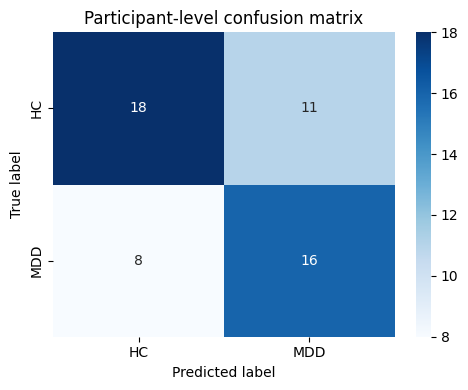

In [14]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(5, 4))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=['HC', 'MDD'], yticklabels=['HC', 'MDD'])
plt.xlabel('Predicted label')
plt.ylabel('True label')
plt.title('Participant-level confusion matrix')
plt.tight_layout()
plt.show()


## 7. Save results

The CSV contains one row per participant, including the out-of-fold decision score and prediction. The fold CSV contains fold-level metrics. These files can be downloaded from Colab or saved to Drive.

In [15]:
RESULT_DIR = Path('/content/fbcsp_results')
RESULT_DIR.mkdir(exist_ok=True)

participant_csv = RESULT_DIR / 'fbcsp_svm_participant_oof_predictions.csv'
fold_csv = RESULT_DIR / 'fbcsp_svm_fold_metrics.csv'
summary_json = RESULT_DIR / 'fbcsp_svm_summary.json'

oof.to_csv(participant_csv, index=False)
fold_results.to_csv(fold_csv, index=False)

summary = {
    'model': 'Filter Bank Common Spatial Pattern + RBF-SVM',
    'cv': 'StratifiedGroupKFold',
    'n_splits': N_SPLITS,
    'grouping': 'subject_id',
    'participant_level': True,
    'label_mapping': {'0': 'Healthy Control', '1': 'MDD'},
    'sampling_rate_hz': SFREQ,
    'bands_hz': BANDS,
    'n_csp_components_per_band': N_CSP_COMPONENTS,
    'accuracy': float(accuracy),
    'balanced_accuracy': float(balanced_acc),
    'roc_auc': float(roc_auc),
    'confusion_matrix_labels_HC_MDD': cm.tolist(),
    'n_participants': int(len(oof)),
    'n_epochs': int(len(X))
}
with open(summary_json, 'w') as f:
    json.dump(summary, f, indent=2)

print('Saved:')
print(participant_csv)
print(fold_csv)
print(summary_json)

# Optional: copy outputs to Google Drive.
# DRIVE_OUT = Path('/content/drive/MyDrive/FBCSP_results')
# DRIVE_OUT.mkdir(exist_ok=True)
# for p in [participant_csv, fold_csv, summary_json]:
#     shutil.copy2(p, DRIVE_OUT / p.name)


Saved:
/content/fbcsp_results/fbcsp_svm_participant_oof_predictions.csv
/content/fbcsp_results/fbcsp_svm_fold_metrics.csv
/content/fbcsp_results/fbcsp_svm_summary.json


In [16]:
# Optional download of result files
from google.colab import files
files.download(str(participant_csv))
files.download(str(fold_csv))
files.download(str(summary_json))


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## 10. Important reporting notes

- Report the **participant-level pooled out-of-fold metrics** as the primary result, not epoch-level metrics.
- Do not tune CSP/SVM parameters on the held-out test participants. If hyperparameter tuning is needed, use an inner group-aware CV inside each outer training fold.
- The filter-bank cache is deterministic preprocessing. CSP, scaling, and SVM are all fitted independently inside each training fold.
- The provided handoff says `X` is `(epochs, 128, 1000)`, `y` is `0=HC, 1=MDD`, and `subject_id` contains participant IDs. Confirm these values against your actual file before interpreting results.
- This notebook does not claim that FBCSP+SVM will outperform EEGNet, ShallowConvNet, or Riemannian SVM. Compare methods using identical participant folds and metrics.
- If the notebook stops because of RAM/disk limits, reduce `FILTER_CHUNK_SIZE` and `FEATURE_CHUNK_SIZE`; do not change the participant grouping.
